# GSM8K dataset analysis

In [1]:

from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

import json, torch, pandas as pd

from eval_gsm8k.utils import extract_predicted_answer

os.chdir('..')

/datassd/home/plazaro/.conda/envs/qwen-tunedlens-math-analysis/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# METADATA
results_paths = {
    "Qwen2.5_BASE": 'eval_results/ig/GSM8K_Qwen__Qwen2.5-14B_2025-06-10_17-18-18',
    "Qwen2.5_GRPO": 'eval_results/ig/GSM8K_outputs__Qwen2_5_14B_GRPO__checkpoint-1500_2025-06-11_10-51-01',
    "Qwen2.5_distil": 'eval_results/ig/GSM8K_deepseek-ai__DeepSeek-R1-Distill-Qwen-14B_2025-06-12_19-03-10',    #! cambiar cuando acabe
}

run_paths = {
    "base": results_paths["Qwen2.5_BASE"],
    "grpo": results_paths["Qwen2.5_GRPO"],
    "distil": results_paths["Qwen2.5_distil"],
}

In [3]:
# MISCELANEOUS FUNCTIONS
def recover_index(run_dir):
    """
    Recover the index from the results directory.
    """
    index_path = Path(run_dir) / "index.json"
    if not index_path.exists():
        raise FileNotFoundError(f"Index file not found: {index_path}")
    
    with open(index_path, 'r', encoding='utf-8') as f:
        index_data = json.load(f)
    
    return pd.DataFrame(index_data)

def print_accuracy(df):
    """
    Print the accuracy of the model based on the DataFrame.
    """
    total = len(df)
    correct = df['correct'].sum()
    accuracy = correct / total * 100
    print(f"Accuracy: {accuracy:.2f}% ({correct}/{total})")
    
def remove_trailing_zeros(tensor: torch.Tensor) -> torch.Tensor:
    # Find the last non-zero index
    non_zero_indices = torch.nonzero(tensor, as_tuple=False).squeeze()
    if non_zero_indices.numel() == 0:
        return tensor[:0]  # All elements are zero
    last_non_zero = non_zero_indices[-1].item()
    return tensor[:last_non_zero + 1]

def extract_attr(row, run_dir, forward_target):
    """
    Extract the inputs and outputs attributions separately
    """
    # Read the data for the selected sample and target
    arr = torch.load(os.path.join(run_dir, row[forward_target]), weights_only=False)
    arr_clean = remove_trailing_zeros(arr)
    # Get input and output token indices
    input_len = len(row['input_tokens'])
    inputs = arr_clean[:input_len]
    outputs = arr_clean[input_len:]
    return inputs, outputs
    
def compute_RS_abs(row, run_dir, forward_target):
    """
    Compute the RS_abs value for a given row.
    """
    # Separate the input and output attributions
    input_attr, output_attr = extract_attr(row, run_dir, forward_target)
    # compute the norms
    input_norm = torch.linalg.norm(input_attr, ord=1)
    output_norm = torch.linalg.norm(output_attr, ord=1)
    # compute the Reasoning-Share_abs value
    rs_abs = output_norm / (input_norm + output_norm)
    return rs_abs.item()

def compute_RS_mean(row, run_dir, forward_target):
    """
    Compute the RS_abs value for a given row.
    """
    # Separate the input and output attributions
    input_attr, output_attr = extract_attr(row, run_dir, forward_target)
    # compute the norms
    input_norm = input_attr.abs().mean()
    output_norm = output_attr.abs().mean()
    # compute the Reasoning-Share_abs value
    rs_abs = output_norm / (input_norm + output_norm)
    if rs_abs.isnan() or rs_abs.isinf():
        print(f"Warning: RS_abs is NaN or Inf for row {row.name}. Returning 0.")
        return 0.0  # I think it's good to return zero, as if there is no reasoning, there is no attr to the reasoning tokens
    return rs_abs.item()

#def compute_RS_net(row, run_dir, forward_target):
#    """
#    Compute the RS_net value for a given row.
#    """
#    # Separate the input and output attributions
#    input_attr, output_attr = extract_attr(row, run_dir, forward_target)
#    # compute the norms
#    input_sum = torch.sum(input_attr, dim=0)
#    output_sum = torch.sum(output_attr, dim=0)
#    sum_norm = (input_sum + output_sum).abs()
#    # compute the g-Share_net value
#    rs_net = output_sum / sum_norm
#    return rs_net.item()

In [4]:
# Stats functions
def descriptive_stats(df, metric):
    grp = df.groupby('run')[metric]
    stats = grp.agg(
        mean   = 'mean',
        median = 'median',
        Q1    = lambda x: x.quantile(0.25),
        Q3    = lambda x: x.quantile(0.75),
        min    = 'min',
        max    = 'max',
    )
    return stats

def cliffs_delta(x, y):
    """Compute Cliff’s delta effect size between two 1D arrays."""
    x = np.asarray(x)
    y = np.asarray(y)
    n1, n2 = len(x), len(y)
    # count how many times xi > yj and xi < yj
    greater = sum(np.sum(xi > y)   for xi in x)
    lesser  = sum(np.sum(xi < y)   for xi in x)
    return (greater - lesser) / (n1 * n2)

def pairwise_stats(df, metric, pairs):
    results = []
    for a, b in pairs:
        #xa = df.loc[df['run']==a, metric]
        #xb = df.loc[df['run']==b, metric]
        # Adapt for nans
        group_a = df[(df['run'] == a) & df[metric].notna()][['id', metric]]
        group_b = df[(df['run'] == b) & df[metric].notna()][['id', metric]]
        # Align by shared IDs
        merged = pd.merge(group_a, group_b, on='id', suffixes=('_a', '_b'))
        # Now as usual
        xa = merged[f'{metric}_a'].values
        xb = merged[f'{metric}_b'].values
        stat, p = wilcoxon(xa, xb)
        med_diff = np.median(xa - xb)
        d = cliffs_delta(xa, xb)
        results.append({
            'Model_A': a,
            'Model_B': b,
            'p-value': p,
            'median_diff': med_diff,
            "cliff's delta": d
        })
    return pd.DataFrame(results)

In [5]:
# Load index data and convert to DataFrames
base_df = recover_index(results_paths["Qwen2.5_BASE"])
grpo_df = recover_index(results_paths["Qwen2.5_GRPO"])
distil_df = recover_index(results_paths["Qwen2.5_distil"])

# Build the big dataframe
for name, df in [
    ("base", base_df),
    ("grpo", grpo_df),
    ("distil", distil_df),
]:
    df["run"] = name
all_df = pd.concat([base_df, grpo_df, distil_df], ignore_index=True)

# Get accuracies
all_df.groupby("run")["correct"].mean()

run
base      0.786960
distil    0.705838
grpo      0.878696
Name: correct, dtype: float64

In [6]:
# Also get accuracies this way
print("Accuracy for Qwen2.5_BASE:")
print_accuracy(base_df)
print("\nAccuracy for Qwen2.5_GRPO:")
print_accuracy(grpo_df)
print("\nAccuracy for Qwen2.5_distil:")
print_accuracy(distil_df)

Accuracy for Qwen2.5_BASE:
Accuracy: 78.70% (1038/1319)

Accuracy for Qwen2.5_GRPO:
Accuracy: 87.87% (1159/1319)

Accuracy for Qwen2.5_distil:
Accuracy: 70.58% (931/1319)


**Tengo explicaciones desperdigadas por ahí**

What the two columns really contain

field	conceptual meaning	how you constructed it

avg_input_target_logprob_attr	⟨Integrated-Gradients attribution⟩ averaged over prompt tokens for the log-probability of the first answer token (the “target”).	first_target_logprob_attr[:input_len].mean()

avg_output_target_logprob_attr	Same attribution but averaged over generated tokens that precede the final numeric answer (your CoT/output tokens).	first_target_logprob_attr[input_len:output_len].mean()


Because Captum’s IG attribution is (gradient × input) integrated along a path, a larger absolute value means “changing this token’s embedding would move the target log-prob more.”

So the relative magnitude of the two averages tells you whether evidence for the answer is located mostly in the prompt or in the chain-of-thought/output so far.

In [7]:
all_df.columns

Index(['id', 'question', 'correct', 'numeric_answer', 'true_answer',
       'input_tokens', 'output_tokens', 'avg_input_target_logprob_attr',
       'avg_output_target_logprob_attr', 'avg_input_target_entropy_attr',
       'avg_output_target_entropy_attr', 'avg_input_seq_logprob_attr',
       'avg_output_seq_logprob_attr', 'avg_input_seq_entropy_attr',
       'avg_output_seq_entropy_attr', 'first_target_logprob_attr_file',
       'first_target_entropy_attr_file', 'seq_logprob_attr_file',
       'seq_entropy_attr_file', 'run'],
      dtype='object')

# First Target Logprob Attr File

In [8]:
# First try this one as sample
target_logp_df = all_df[['id', 'question', 'run', 'correct', 'input_tokens', 'output_tokens',
                         'first_target_logprob_attr_file']].copy()
target_logp_df["rs_abs"] = target_logp_df.apply(
    lambda row: compute_RS_abs(row, run_paths[row['run']], 'first_target_logprob_attr_file'), axis=1)
#target_logp_df["rs_net"] = target_logp_df.apply(
#    lambda row: compute_RS_net(row, run_paths[row['run']], 'first_target_logprob_attr_file'), axis=1)
target_logp_df["rs_mean"] = target_logp_df.apply(
    lambda row: compute_RS_mean(row, run_paths[row['run']], 'first_target_logprob_attr_file'), axis=1)

In [9]:
# Now compute statistics
target_logp_df = target_logp_df[['id', 'question', 'run', 'correct', 'rs_abs', 'rs_mean']].copy()
# Descriptive statistics
print("=== rs_abs ===")
print(descriptive_stats(target_logp_df, 'rs_abs'), "\n")
#print("=== rs_net ===")
#print(descriptive_stats(target_logp_df, 'rs_net'), "\n")
print("=== rs_mean ===")
print(descriptive_stats(target_logp_df, 'rs_mean'), "\n")

=== rs_abs ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.319803  0.297042  0.209346  0.409473  0.020525  0.812359
distil  0.873849  0.909777  0.866448  0.943266  0.000000  0.995267
grpo    0.633149  0.627705  0.547223  0.729056  0.176097  0.989475 

=== rs_mean ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.235568  0.216207  0.133619  0.322369  0.008883  0.854508
distil  0.418101  0.434930  0.298825  0.537452  0.000000  0.872741
grpo    0.305612  0.291991  0.203843  0.400050  0.043588  0.765476 



In [10]:
# Now pairwise statistics
# define your run‐name pairs
pairs = [('base','grpo'), ('base','distil'), ('grpo','distil')]

print("Pairwise for rs_abs:")
print(pairwise_stats(target_logp_df, 'rs_abs', pairs), "\n")

#print("Pairwise for rs_net:")
#print(pairwise_stats(target_logp_df, 'rs_net', pairs), "\n")

print("Pairwise for rs_mean:")
print(pairwise_stats(target_logp_df, 'rs_mean', pairs), "\n")

Pairwise for rs_abs:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  8.134357e-207    -0.325483      -0.884327
1    base  distil  5.356158e-213    -0.590859      -0.956231
2    grpo  distil  7.527884e-173    -0.261971      -0.860930 

Pairwise for rs_mean:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo   1.037550e-37    -0.069355      -0.298010
1    base  distil  8.321054e-132    -0.192962      -0.602306
2    grpo  distil   2.394512e-69    -0.125403      -0.411972 



🎯 What This Tells You
✅ 1. Hypothesis supported: Finetuned models (grpo, distil) focus more on reasoning.
This is true both in total share (RS_abs) and in per-token influence (RS_mean).

Distil especially allocates attribution to reasoning tokens both more widely and more densely.

⚠️ 2. But reasoning isn't always helpful (RS_net):
Base model, though less focused on reasoning, tends to benefit more when it does focus — RS_net is positive.

Distil and grpo assign more attribution to reasoning, but often that reasoning reduces the predicted logprob (RS_net negative).

🔍 3. Length bias is real — and now accounted for
The huge jump from base → distil in RS_abs (+0.59) is mostly length-driven.

The remaining shift in RS_mean (+0.19) shows real change in attribution per token — smaller, but still strong.

🧠 Suggested framing for your paper:
"Finetuned models increasingly allocate attribution to reasoning segments, with Distil showing the strongest shift (RS_mean median +0.19, p < 1e−130). This confirms our hypothesis that RL and distillation push models to rely more heavily on their generated rationales. However, the signed attribution (RS_net) reveals that this increased focus is not uniformly beneficial: reasoning tokens often reduce confidence in the correct answer, suggesting that the model’s internal reasoning may be misleading or misaligned."

Let me know if you’d like a version of this as a figure caption or section write-up!

/tmp/ipykernel_1778312/1851318474.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


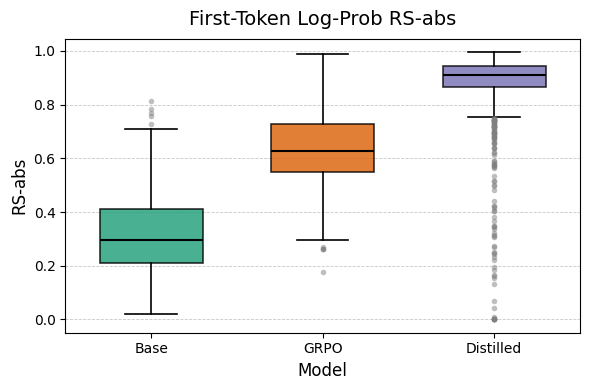

In [11]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [target_logp_df.loc[target_logp_df['run']==r, 'rs_abs'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=True,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-abs', fontsize=12)
ax.set_title('First-Token Log-Prob RS-abs', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

/tmp/ipykernel_1778312/3603268524.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


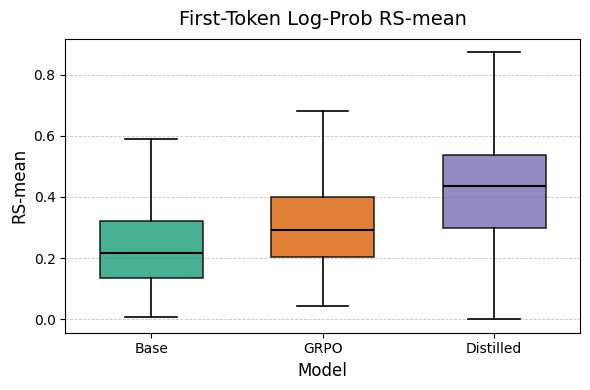

In [12]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [target_logp_df.loc[target_logp_df['run']==r, 'rs_mean'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=False,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-mean', fontsize=12)
ax.set_title('First-Token Log-Prob RS-mean', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

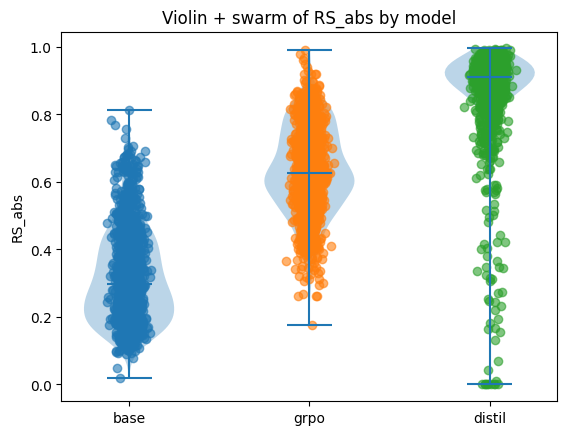

In [13]:
# Violin plot
plt.figure()
runs = target_logp_df['run'].unique()
data = [target_logp_df.loc[target_logp_df['run']==r, 'rs_abs'].values
        for r in runs]

# violin
plt.violinplot(data, positions=np.arange(len(runs)), showmedians=True)

# swarm—jittered scatter
for i, vals in enumerate(data):
    x = np.random.normal(i, 0.04, size=len(vals))
    plt.scatter(x, vals, alpha=0.6)

plt.xticks(np.arange(len(runs)), runs)
plt.ylabel('RS_abs')
plt.title('Violin + swarm of RS_abs by model')
plt.show()

In [14]:
all_df.iloc[0]['question']

"Q: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?\nA:"

# First Target Entropy Attr File

In [15]:
# First try this one as sample
target_ent_df = all_df[['id', 'question', 'run', 'correct', 'input_tokens', 'output_tokens',
                         'first_target_entropy_attr_file']].copy()
target_ent_df["rs_abs"] = target_ent_df.apply(
    lambda row: compute_RS_abs(row, run_paths[row['run']], 'first_target_entropy_attr_file'), axis=1)
target_ent_df["rs_mean"] = target_ent_df.apply(
    lambda row: compute_RS_mean(row, run_paths[row['run']], 'first_target_entropy_attr_file'), axis=1)

In [16]:
# Now compute statistics
target_ent_df = target_ent_df[['id', 'question', 'run', 'correct', 'rs_abs', 'rs_mean']].copy()
# Descriptive statistics
print("=== rs_abs ===")
print(descriptive_stats(target_ent_df, 'rs_abs'), "\n")
print("=== rs_mean ===")
print(descriptive_stats(target_ent_df, 'rs_mean'), "\n")

=== rs_abs ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.332858  0.312017  0.226785  0.422933  0.006147  0.804386
distil  0.737966  0.755522  0.653814  0.878971  0.000000  0.992136
grpo    0.539146  0.503144  0.381650  0.684634  0.217947  0.988121 

=== rs_mean ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.244420  0.226373  0.141103  0.340957  0.017172  0.763302
distil  0.232969  0.218592  0.130727  0.320786  0.000000  0.872491
grpo    0.259471  0.222885  0.108227  0.407630  0.016548  0.714369 



In [17]:
# Now pairwise statistics
# define your run‐name pairs
pairs = [('base','grpo'), ('base','distil'), ('grpo','distil')]

print("Pairwise for rs_abs:")
print(pairwise_stats(target_ent_df, 'rs_abs', pairs), "\n")
print("Pairwise for rs_mean:")
print(pairwise_stats(target_ent_df, 'rs_mean', pairs), "\n")

Pairwise for rs_abs:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  4.251097e-145    -0.193367      -0.640359
1    base  distil  1.181019e-204    -0.436416      -0.891622
2    grpo  distil  6.855793e-119    -0.221247      -0.580449 

Pairwise for rs_mean:
  Model_A Model_B   p-value  median_diff  cliff's delta
0    base    grpo  0.075512    -0.000731      -0.008002
1    base  distil  0.036892     0.008345       0.054530
2    grpo  distil  0.000099     0.008966       0.048939 



/tmp/ipykernel_1778312/11760908.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


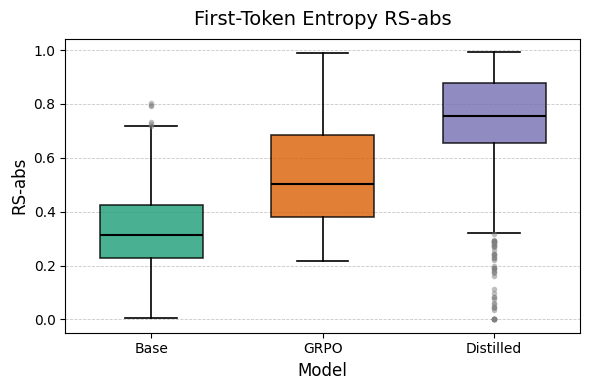

In [18]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [target_ent_df.loc[target_ent_df['run']==r, 'rs_abs'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=True,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-abs', fontsize=12)
ax.set_title('First-Token Entropy RS-abs', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

/tmp/ipykernel_1778312/783157444.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


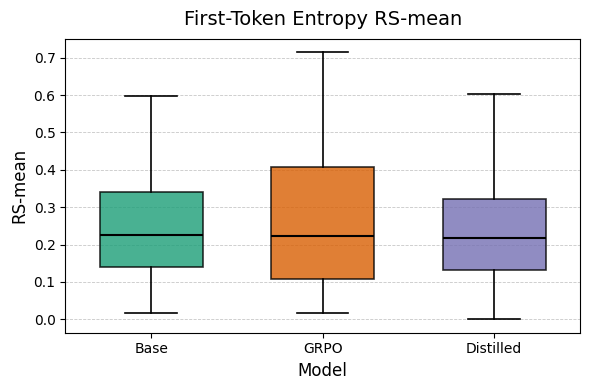

In [19]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [target_ent_df.loc[target_ent_df['run']==r, 'rs_mean'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=False,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-mean', fontsize=12)
ax.set_title('First-Token Entropy RS-mean', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

# Seq Logprob Attr File

In [20]:
# First try this one as sample
seq_logp_df = all_df[['id', 'question', 'run', 'correct', 'input_tokens', 'output_tokens',
                         'seq_logprob_attr_file']].copy()
seq_logp_df["rs_abs"] = seq_logp_df.apply(
    lambda row: compute_RS_abs(row, run_paths[row['run']], 'seq_logprob_attr_file'), axis=1)
seq_logp_df["rs_mean"] = seq_logp_df.apply(
    lambda row: compute_RS_mean(row, run_paths[row['run']], 'seq_logprob_attr_file'), axis=1)

In [21]:
# Now compute statistics
seq_logp_df = seq_logp_df[['id', 'question', 'run', 'correct', 'rs_abs', 'rs_mean']].copy()
# Descriptive statistics
print("=== rs_abs ===")
print(descriptive_stats(seq_logp_df, 'rs_abs'), "\n")
print("=== rs_mean ===")
print(descriptive_stats(seq_logp_df, 'rs_mean'), "\n")

=== rs_abs ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.299053  0.274261  0.189736  0.382721  0.057232  0.864542
distil  0.723497  0.744945  0.600924  0.912232  0.000000  0.993532
grpo    0.657676  0.650744  0.563639  0.757603  0.176338  0.985907 

=== rs_mean ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.221419  0.205742  0.110131  0.308924  0.008911  0.914381
distil  0.240617  0.217352  0.131108  0.326809  0.000000  0.906437
grpo    0.332280  0.321327  0.221511  0.433810  0.045578  0.756254 



In [22]:
# Now pairwise statistics
# define your run‐name pairs
pairs = [('base','grpo'), ('base','distil'), ('grpo','distil')]

print("Pairwise for rs_abs:")
print(pairwise_stats(seq_logp_df, 'rs_abs', pairs), "\n")
print("Pairwise for rs_mean:")
print(pairwise_stats(seq_logp_df, 'rs_mean', pairs), "\n")

Pairwise for rs_abs:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  6.185011e-212    -0.367168      -0.918457
1    base  distil  5.183234e-199    -0.453996      -0.865514
2    grpo  distil   1.376701e-27    -0.088067      -0.276729 

Pairwise for rs_mean:
  Model_A Model_B       p-value  median_diff  cliff's delta
0    base    grpo  1.285830e-75    -0.108345      -0.434548
1    base  distil  1.164456e-03    -0.018677      -0.071787
2    grpo  distil  1.153555e-56     0.094741       0.372838 



/tmp/ipykernel_1778312/616131165.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


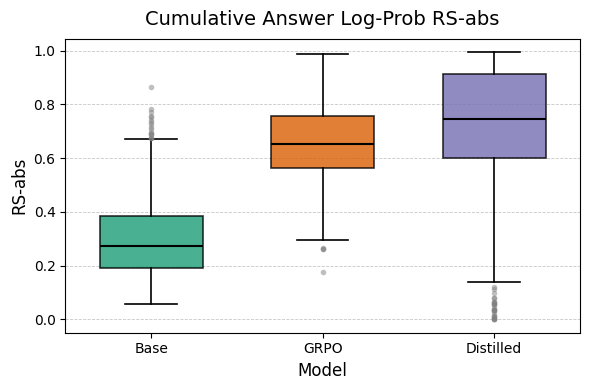

In [23]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [seq_logp_df.loc[seq_logp_df['run']==r, 'rs_abs'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=True,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-abs', fontsize=12)
ax.set_title('Cumulative Answer Log-Prob RS-abs', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

/tmp/ipykernel_1778312/2484319325.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


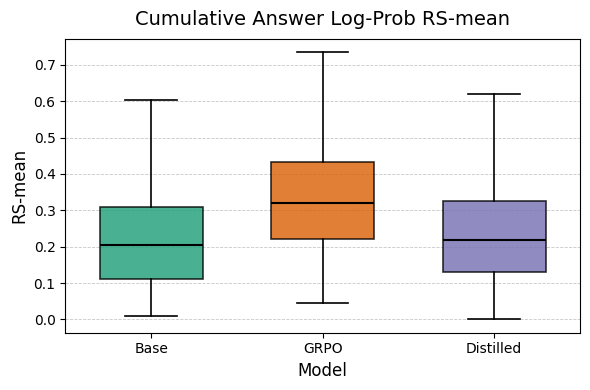

In [24]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [seq_logp_df.loc[seq_logp_df['run']==r, 'rs_mean'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=False,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-mean', fontsize=12)
ax.set_title('Cumulative Answer Log-Prob RS-mean', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

# Seq Entropy Attr File

In [25]:
# First try this one as sample
seq_ent_df = all_df[['id', 'question', 'run', 'correct', 'input_tokens', 'output_tokens',
                         'seq_entropy_attr_file']].copy()
seq_ent_df["rs_abs"] = seq_ent_df.apply(
    lambda row: compute_RS_abs(row, run_paths[row['run']], 'seq_entropy_attr_file'), axis=1)
seq_ent_df["rs_mean"] = seq_ent_df.apply(
    lambda row: compute_RS_mean(row, run_paths[row['run']], 'seq_entropy_attr_file'), axis=1)

In [26]:
# Now compute statistics
seq_ent_df = seq_ent_df[['id', 'question', 'run', 'correct', 'rs_abs', 'rs_mean']].copy()
# Descriptive statistics
print("=== rs_abs ===")
print(descriptive_stats(seq_ent_df, 'rs_abs'), "\n")
print("=== rs_mean ===")
print(descriptive_stats(seq_ent_df, 'rs_mean'), "\n")

=== rs_abs ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.294742  0.270723  0.186992  0.380301  0.041827  0.834419
distil  0.733974  0.747706  0.637659  0.893177  0.000000  0.989833
grpo    0.545755  0.510620  0.357826  0.732547  0.182172  0.988136 

=== rs_mean ===
            mean    median        Q1        Q3       min       max
run                                                               
base    0.215091  0.191536  0.106132  0.300422  0.012851  0.762453
distil  0.235213  0.215633  0.131240  0.316096  0.000000  0.974825
grpo    0.271087  0.243108  0.102908  0.425424  0.015123  0.733786 



In [27]:
# Now pairwise statistics
# define your run‐name pairs
pairs = [('base','grpo'), ('base','distil'), ('grpo','distil')]

print("Pairwise for rs_abs:")
print(pairwise_stats(seq_ent_df, 'rs_abs', pairs), "\n")
print("Pairwise for rs_mean:")
print(pairwise_stats(seq_ent_df, 'rs_mean', pairs), "\n")

Pairwise for rs_abs:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  5.245151e-159    -0.232665      -0.691569
1    base  distil  1.543162e-208    -0.460261      -0.907401
2    grpo  distil  9.999510e-103    -0.196473      -0.503644 

Pairwise for rs_mean:
  Model_A Model_B       p-value  median_diff  cliff's delta
0    base    grpo  1.334819e-16    -0.040435      -0.153800
1    base  distil  3.822025e-04    -0.021192      -0.088440
2    grpo  distil  3.026857e-08     0.023944       0.078411 



/tmp/ipykernel_1778312/1997943667.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


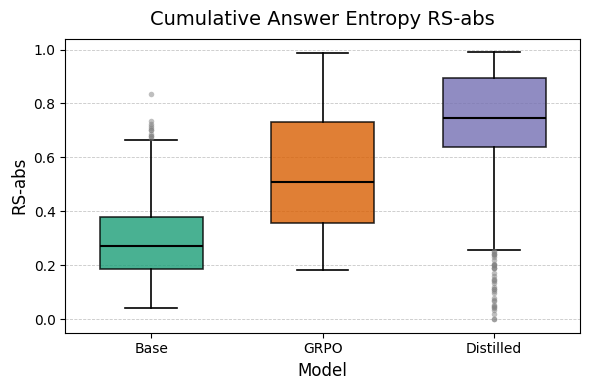

In [28]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [seq_ent_df.loc[seq_ent_df['run']==r, 'rs_abs'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=True,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-abs', fontsize=12)
ax.set_title('Cumulative Answer Entropy RS-abs', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()

/tmp/ipykernel_1778312/2670672126.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


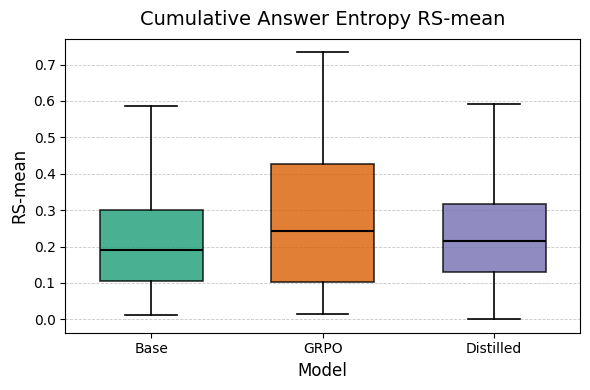

In [29]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [seq_ent_df.loc[seq_ent_df['run']==r, 'rs_mean'].values for r in runs]

# ——————————————————————————
# Wada-inspired palette (beniiro, aotake, kigiki)
# ——————————————————————————
colors = ['#1b9e77',  
          '#d95f02',  
          '#7570b3']  

# ——————————————————————————
# Plot
# ——————————————————————————
fig, ax = plt.subplots(figsize=(6, 4))

box = ax.boxplot(
    data,
    labels=["Base", "GRPO", "Distilled"],
    notch=False,
    patch_artist=True,
    showfliers=False,
    widths=0.6,
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
    medianprops=dict(color='k', linewidth=1.5),
    whiskerprops=dict(color='k', linewidth=1.2),
    capprops=dict(color='k', linewidth=1.2),
    boxprops=dict(linewidth=1.2)
)

# fill each box with its Wada color
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# axis labels & grid
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RS-mean', fontsize=12)
ax.set_title('Cumulative Answer Entropy RS-mean', fontsize=14, pad=10)
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

# tighten
plt.tight_layout()
plt.show()